# Análisis exploratorio (EDA) · Créditos vehiculares
**Tarea 2 del reto · Soporte 3 · Rol: Análisis de datos**

Pregunta general: ¿cómo aprobar más clientes viables y bajar el impago de los aprobados por debajo de **21,71 %**?

| # | Gráfico | Responde a |
|---|---|---|
| 1 | Tabla pregunta → gráfico | PE1, PE2 |
| 2 | Histograma + KDE (LTV, monto) | Perfil del préstamo |
| 3 | Boxplot y violín por pago / impago | PE2 Riesgo |
| 4 | Barras: impago por buró y sucursal; 100 % apiladas | PE1 Ventas, PE2 Riesgo |
| 5 | Scatter / bubble monto vs LTV | PE2 Riesgo |
| 6 | Mapa de calor de correlaciones | Justifica variables redundantes |
| 7 | Pairplot | Relaciones entre variables clave |
| 8 | Interactivo (Plotly) por sucursal | PE1 Ventas · reutilizable en Dash |

Usa la misma función de preparación que el modelo (`limpieza_datos/preparacion.py`).

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sys.path.insert(0, os.path.abspath("../limpieza_datos"))
import preparacion as prep

sns.set_theme(style="whitegrid")
os.makedirs("graficos", exist_ok=True)
LIMITE = prep.LIMITE_IMPAGO * 100
ORDEN_BURO = ["Muy bajo", "Bajo", "Sin puntaje", "Sin historial", "Medio", "Alto", "Muy alto"]

df = prep.preparar(pd.read_csv("../train.csv"))          # pasos 1-5 de la limpieza
df["ESTADO"] = df["LOAN_DEFAULT"].map({0: "Paga", 1: "No paga"})
df["GRUPO_EDAD"] = pd.cut(df["EDAD"], [0, 25, 30, 35, 45, 120], labels=["18-25", "26-30", "31-35", "36-45", "46+"])
df["GRUPO_LTV"] = pd.cut(df["LTV"], [0, 60, 70, 80, 90, 100], labels=["<=60", "60-70", "70-80", "80-90", ">90"])
print(df.shape)
print(f"Impago total: {df['LOAN_DEFAULT'].mean():.2%}")
df.head()

(233154, 49)
Impago total: 21.71%


,UNIQUEID,DISBURSED_AMOUNT,ASSET_COST,LTV,BRANCH_ID,SUPPLIER_ID,MANUFACTURER_ID,CURRENT_PINCODE_ID,DATE_OF_BIRTH,EMPLOYMENT_TYPE,...,NO_OF_INQUIRIES,LOAN_DEFAULT,MES,EDAD,HISTORIAL_CRED_M,ANTIG_PROM_CUENTAS_M,CNS_GRUPO,ESTADO,GRUPO_EDAD,GRUPO_LTV
0,420825,50578,58400,89.55,67,22807,45,1441,01-01-1984,Salaried,...,0,0,8,34,0.0,0.0,Sin historial,Paga,31-35,80-90
1,537409,47145,65550,73.23,67,22807,45,1502,31-07-1985,Self employed,...,0,1,9,33,23.0,23.0,Medio,No paga,31-35,70-80
2,417566,53278,61360,89.63,67,22807,45,1497,24-08-1985,Self employed,...,0,0,8,32,0.0,0.0,Sin historial,Paga,31-35,80-90
3,624493,57513,66113,88.48,67,22807,45,1501,30-12-1993,Self employed,...,1,1,10,24,15.0,8.0,Muy alto,No paga,18-25,80-90
4,539055,52378,60300,88.39,67,22807,45,1495,09-12-1977,Self employed,...,1,1,9,40,0.0,0.0,Sin historial,No paga,36-45,80-90


## 0 · Estadísticas descriptivas

In [2]:
num = ["DISBURSED_AMOUNT", "ASSET_COST", "LTV", "EDAD", "PRI_NO_OF_ACCTS", "PRI_ACTIVE_ACCTS",
       "PRI_OVERDUE_ACCTS", "PRI_SANCTIONED_AMOUNT", "HISTORIAL_CRED_M", "NO_OF_INQUIRIES"]
desc = df[num].describe(percentiles=[.25, .5, .75, .99]).T
desc["% ceros"] = (df[num] == 0).mean() * 100
display(desc.round(2))

# Mediana de cada variable según pague o no
display(df.groupby("ESTADO")[num].median().T.round(1))

,count,mean,std,min,25%,50%,75%,99%,max,% ceros
DISBURSED_AMOUNT,233154.0,54356.99,12971.31,13320.00,47145.00,53803.0,60413.00,95391.00,9.905720e+05,0.00
ASSET_COST,233154.0,75865.07,18944.78,37000.00,65717.00,70946.0,79201.75,156016.00,1.628992e+06,0.00
LTV,233154.0,74.75,11.46,10.03,68.88,76.8,83.67,89.95,9.500000e+01,0.00
EDAD,233154.0,33.94,9.82,18.00,26.00,32.0,41.00,58.00,6.900000e+01,0.00
PRI_NO_OF_ACCTS,233154.0,2.44,5.22,0.00,0.00,0.0,3.00,23.00,4.530000e+02,50.16
PRI_ACTIVE_ACCTS,233154.0,1.04,1.94,0.00,0.00,0.0,1.00,9.00,1.440000e+02,58.77
PRI_OVERDUE_ACCTS,233154.0,0.16,0.55,0.00,0.00,0.0,0.00,2.00,2.500000e+01,88.73
PRI_SANCTIONED_AMOUNT,233154.0,218503.86,2374794.13,0.00,0.00,0.0,62500.00,3467119.37,1.000000e+09,59.23
HISTORIAL_CRED_M,233154.0,16.25,28.58,0.00,0.00,0.0,24.00,140.00,4.680000e+02,51.09
NO_OF_INQUIRIES,233154.0,0.21,0.71,0.00,0.00,0.0,0.00,3.00,3.600000e+01,86.62


ESTADO,No paga,Paga
DISBURSED_AMOUNT,55459.0,53303.0
ASSET_COST,71326.0,70845.0
LTV,79.1,76.0
EDAD,31.0,32.0
PRI_NO_OF_ACCTS,0.0,1.0
PRI_ACTIVE_ACCTS,0.0,0.0
PRI_OVERDUE_ACCTS,0.0,0.0
PRI_SANCTIONED_AMOUNT,0.0,0.0
HISTORIAL_CRED_M,0.0,0.0
NO_OF_INQUIRIES,0.0,0.0


## 1 · ¿Qué gráfico usar para cada pregunta?

| Pregunta | Gráfico |
|---|---|
| ¿Cómo se distribuye el LTV y el monto? | Histograma + KDE |
| ¿Los que no pagan tienen LTV o edad distinta? | Boxplot / violín por estado |
| ¿Qué categoría del buró y qué sucursal tienen más impago? | Barras horizontales ordenadas |
| ¿Cambia la proporción de impago según empleo o LTV? | Barras 100 % apiladas |
| ¿Monto y LTV juntos separan a quienes no pagan? | Scatter con color |
| ¿Qué variables son redundantes? | Mapa de calor de correlaciones |

## 2 · Distribuciones: histograma + KDE con la mediana

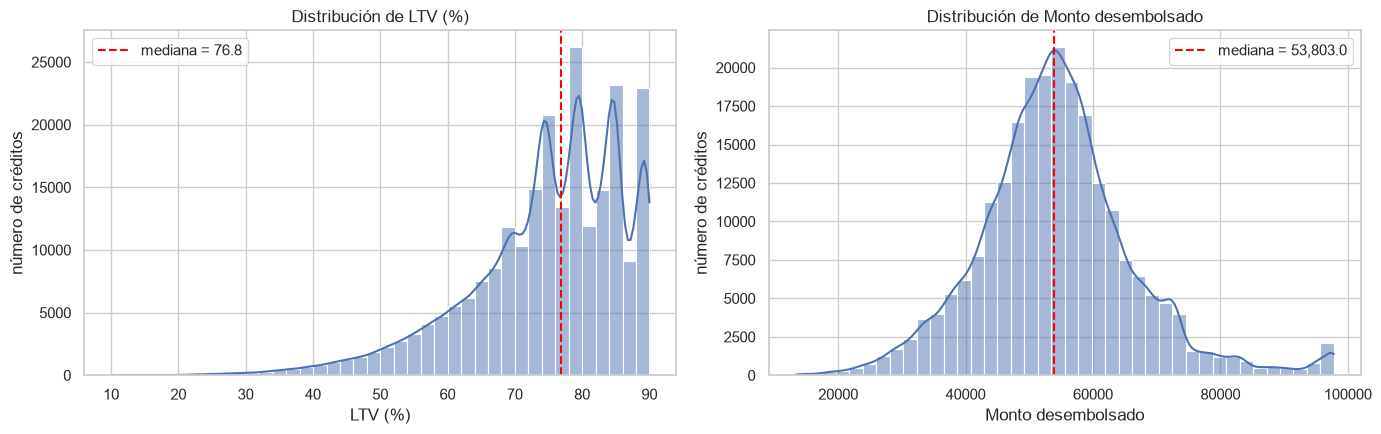

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col, etiqueta in [(axes[0], "LTV", "LTV (%)"), (axes[1], "DISBURSED_AMOUNT", "Monto desembolsado")]:
    mediana = df[col].median()
    datos = df[col].clip(upper=df[col].quantile(0.995))   # recorte solo visual
    sns.histplot(datos, bins=40, kde=True, ax=ax)
    ax.axvline(mediana, color="red", ls="--", label=f"mediana = {mediana:,.1f}")
    ax.set(xlabel=etiqueta, ylabel="número de créditos", title=f"Distribución de {etiqueta}")
    ax.legend()
plt.tight_layout(); plt.savefig("graficos/01_histogramas.png", dpi=150); plt.show()

**Observación:** el LTV se concentra entre 70 % y 90 % (mediana 76,8 %), con picos en 75, 80, 85 y 90 %: parecen porcentajes de financiamiento estándar que ofrece la empresa. El monto desembolsado tiene forma de campana alrededor de 53 800, con cola a la derecha. *La barra alta al final del monto es efecto del recorte visual en el percentil 99,5, no un dato real.*

## 3 · Por grupo: boxplot de LTV y violín de edad según pago

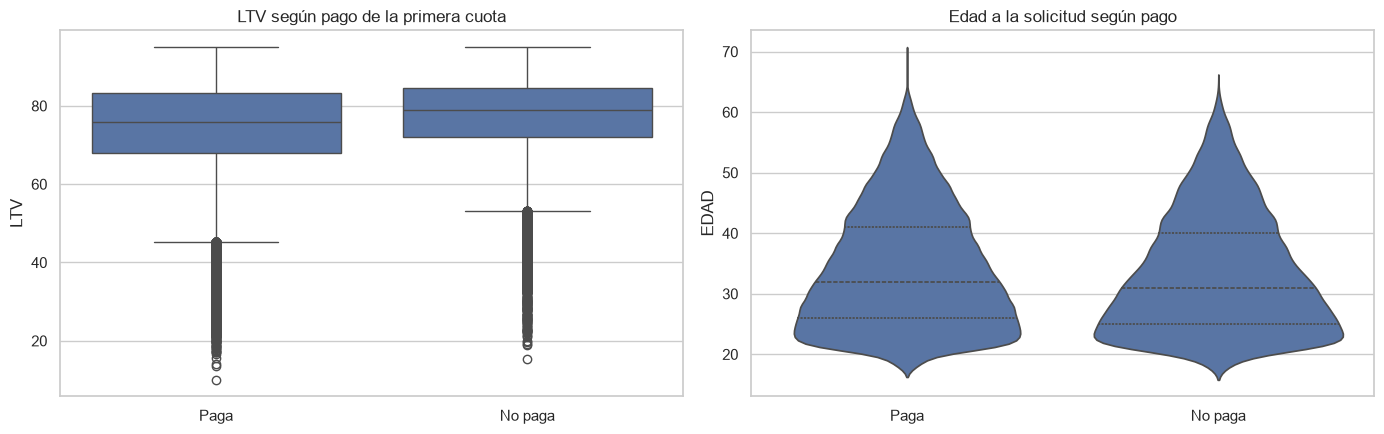

,LTV,EDAD
ESTADO,,
No paga,79.06,31.0
Paga,76.00,32.0


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=df, x="ESTADO", y="LTV", order=["Paga", "No paga"], ax=axes[0])
axes[0].set(title="LTV según pago de la primera cuota", xlabel="")
sns.violinplot(data=df, x="ESTADO", y="EDAD", order=["Paga", "No paga"], inner="quartile", ax=axes[1])
axes[1].set(title="Edad a la solicitud según pago", xlabel="")
plt.tight_layout(); plt.savefig("graficos/02_box_violin.png", dpi=150); plt.show()

display(df.groupby("ESTADO")[["LTV", "EDAD"]].median())

**Observación:** quienes no pagan piden un LTV más alto (mediana ≈ 79 % frente a 76 %) y toda su caja está desplazada hacia arriba. La edad casi no cambia (mediana 31 frente a 32 años; los que no pagan son apenas más jóvenes). **El LTV separa mejor a los dos grupos que la edad.**

## 4 · Barras: impago por buró, por sucursal y proporciones 100 % apiladas

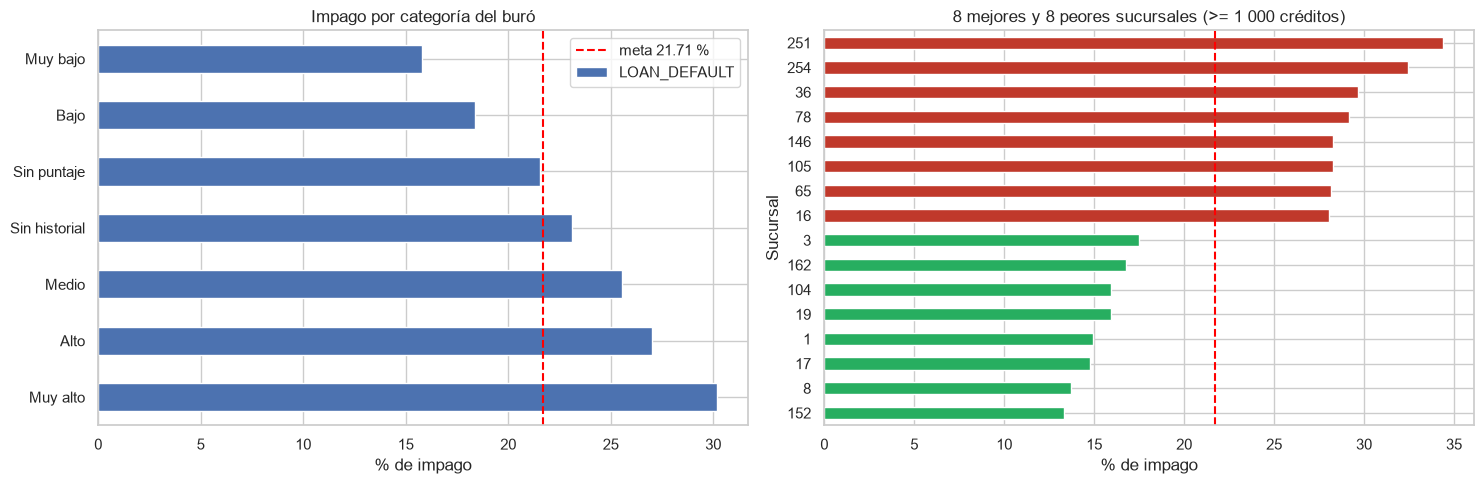

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

buro = df.groupby("CNS_GRUPO")["LOAN_DEFAULT"].mean().reindex(ORDEN_BURO) * 100
buro.plot.barh(ax=axes[0], color="#4C72B0")
axes[0].axvline(LIMITE, color="red", ls="--", label=f"meta {LIMITE:.2f} %")
axes[0].invert_yaxis(); axes[0].legend()
axes[0].set(xlabel="% de impago", ylabel="", title="Impago por categoría del buró")

suc = df.groupby("BRANCH_ID")["LOAN_DEFAULT"].agg(["size", "mean"])
suc = suc[suc["size"] >= 1000].sort_values("mean")
extremos = pd.concat([suc.head(8), suc.tail(8)])["mean"] * 100
extremos.plot.barh(ax=axes[1], color=np.where(extremos > LIMITE, "#c0392b", "#27ae60"))
axes[1].axvline(LIMITE, color="red", ls="--")
axes[1].set(xlabel="% de impago", ylabel="Sucursal", title="8 mejores y 8 peores sucursales (>= 1 000 créditos)")
plt.tight_layout(); plt.savefig("graficos/03_barras_buro_sucursal.png", dpi=150); plt.show()

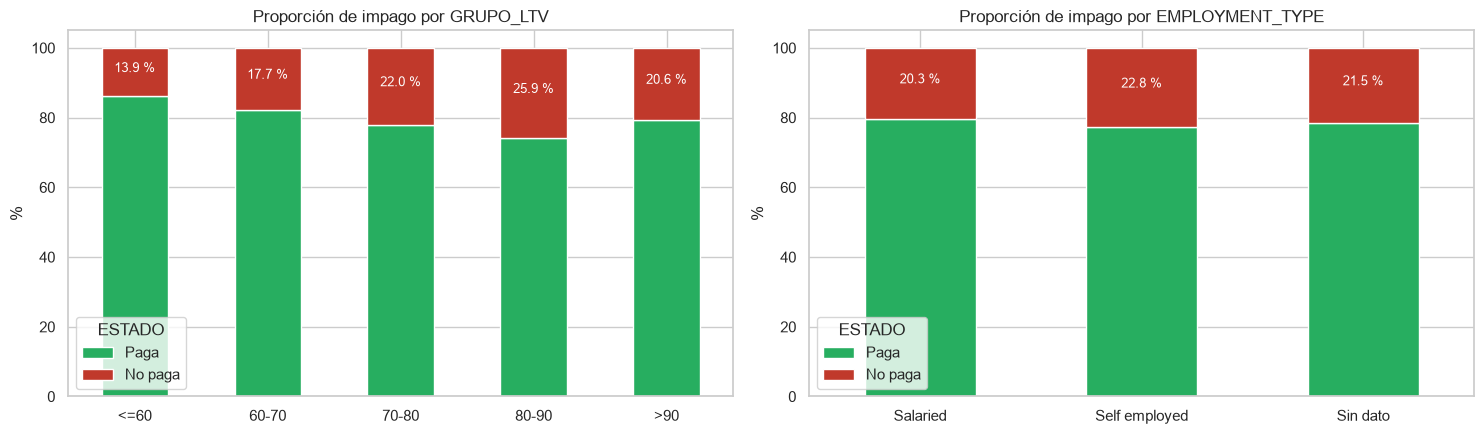

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, col in [(axes[0], "GRUPO_LTV"), (axes[1], "EMPLOYMENT_TYPE")]:
    tabla = pd.crosstab(df[col], df["ESTADO"], normalize="index")[["Paga", "No paga"]] * 100
    tabla.plot.bar(stacked=True, ax=ax, color=["#27ae60", "#c0392b"], rot=0)
    for i, v in enumerate(tabla["No paga"]):
        ax.text(i, 100 - v / 2, f"{v:.1f} %", ha="center", color="white", fontsize=9)
    ax.set(ylabel="%", xlabel="", title=f"Proporción de impago por {col}")
plt.tight_layout(); plt.savefig("graficos/04_barras_apiladas.png", dpi=150); plt.show()

**Observación:**
- **Buró:** el impago sube de forma ordenada con el riesgo: 15,8 % (muy bajo) → 30,2 % (muy alto). "Sin historial" (la mitad de los clientes) está en 23,1 %, **por encima de la meta**, y la regla del buró no puede distinguir dentro de ese grupo.
- **Sucursal:** entre sucursales con más de 1 000 créditos el impago va de 13,3 % (152) a 34,4 % (251): 2,6 veces más. 39 de las 82 sucursales están sobre la meta y concentran el 44,5 % de los créditos.
- **LTV por tramos:** el impago sube de 13,9 % (LTV ≤ 60 %) a 25,9 % (80–90 %). El tramo > 90 % baja a 20,6 %, pero solo tiene 883 créditos (0,4 %): es poco estable y conviene consultarlo con el negocio.
- **Empleo:** independientes 22,8 % frente a asalariados 20,3 %.

## 5 · Scatter / bubble: monto vs LTV, color por pago

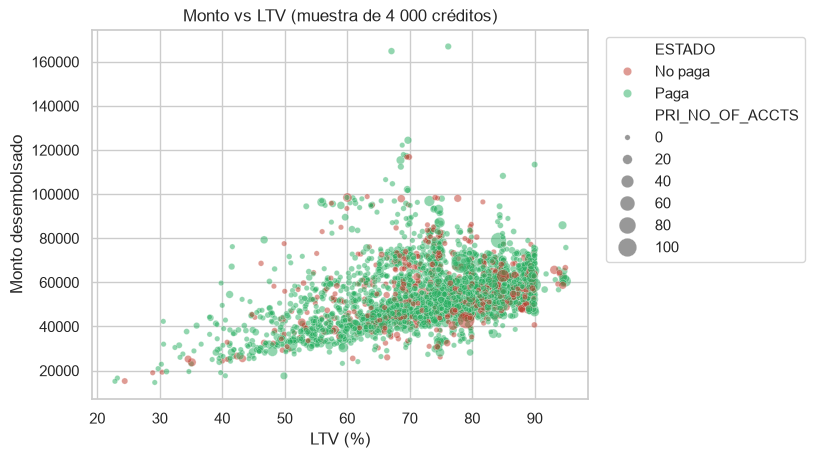

In [7]:
muestra = df.sample(4000, random_state=42)   # muestra para que el gráfico sea legible
ax = sns.scatterplot(data=muestra, x="LTV", y="DISBURSED_AMOUNT", hue="ESTADO", size="PRI_NO_OF_ACCTS",
                     sizes=(15, 200), alpha=0.5, palette={"Paga": "#27ae60", "No paga": "#c0392b"})
ax.set(xlabel="LTV (%)", ylabel="Monto desembolsado", title="Monto vs LTV (muestra de 4 000 créditos)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.savefig("graficos/05_scatter.png", dpi=150, bbox_inches="tight"); plt.show()

**Observación:** los puntos rojos (no paga) y verdes (paga) están **mezclados**: no hay una zona de monto y LTV donde solo haya impago. Ninguna variable sola separa a los clientes; por eso la capacidad predictiva es moderada y hay que combinar varias variables en un modelo.

## 6 · Correlaciones: justifica las variables redundantes
Solo clientes **con historial**: los ceros de quienes no tienen historial inflan la correlación.

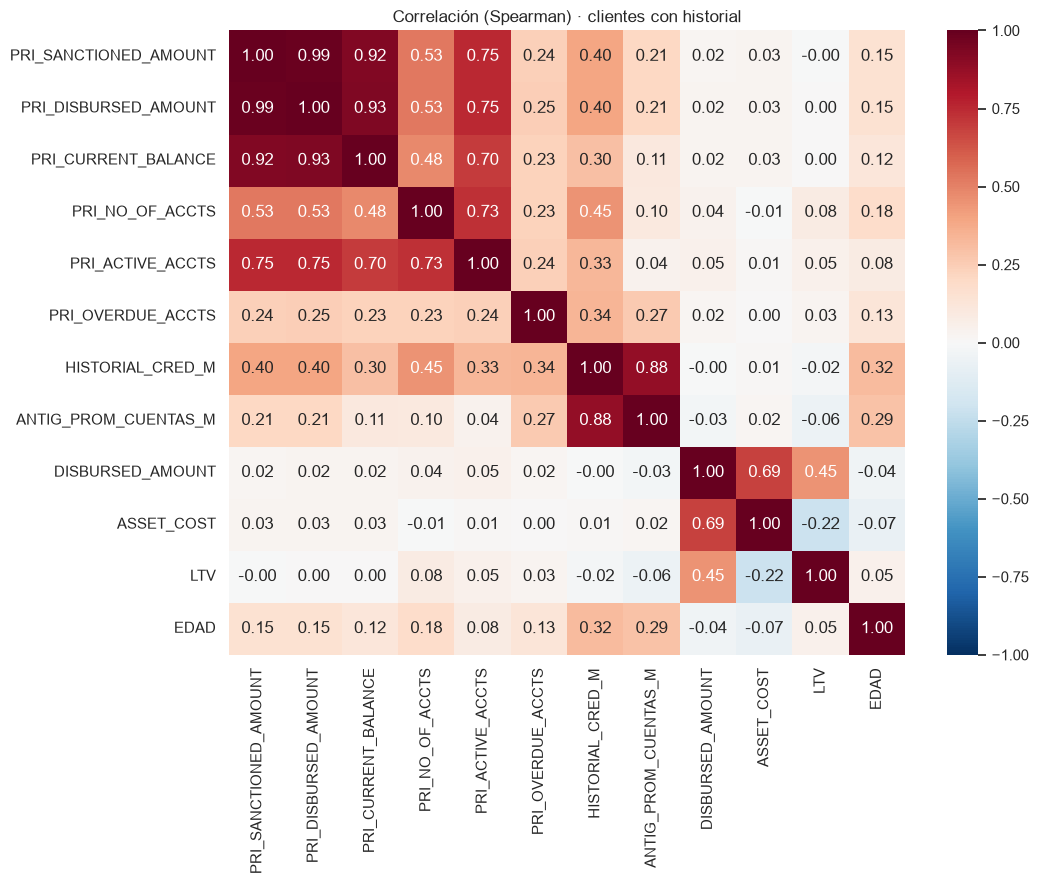

In [8]:
cols = ["PRI_SANCTIONED_AMOUNT", "PRI_DISBURSED_AMOUNT", "PRI_CURRENT_BALANCE", "PRI_NO_OF_ACCTS",
        "PRI_ACTIVE_ACCTS", "PRI_OVERDUE_ACCTS", "HISTORIAL_CRED_M", "ANTIG_PROM_CUENTAS_M",
        "DISBURSED_AMOUNT", "ASSET_COST", "LTV", "EDAD"]
con_historial = df[df["PRI_NO_OF_ACCTS"] > 0]
corr = con_historial[cols].corr(method="spearman")
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlación (Spearman) · clientes con historial")
plt.tight_layout(); plt.savefig("graficos/06_correlaciones.png", dpi=150); plt.show()

**Observación:** confirma las variables redundantes eliminadas en la limpieza: montos de cuentas principales (aprobado, desembolsado y saldo: 0,92 – 0,99) e historial con antigüedad promedio (0,88). Monto y valor del vehículo correlacionan 0,69 y LTV es su cociente, por eso basta con LTV y monto. El resto de variables tiene correlaciones bajas: aportan información distinta.

## 7 · Pairplot de variables clave

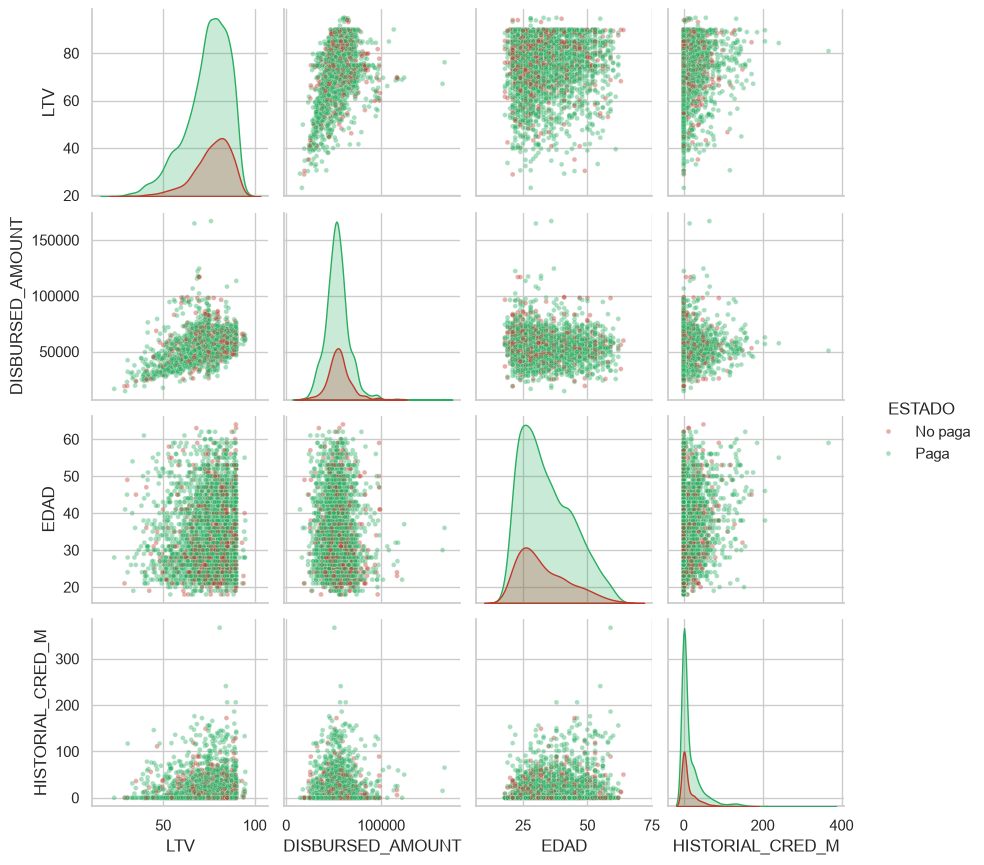

In [9]:
clave = ["LTV", "DISBURSED_AMOUNT", "EDAD", "HISTORIAL_CRED_M"]
g = sns.pairplot(df.sample(3000, random_state=42)[clave + ["ESTADO"]], hue="ESTADO", height=2.2,
                 plot_kws={"alpha": 0.4, "s": 12}, palette={"Paga": "#27ae60", "No paga": "#c0392b"})
g.savefig("graficos/07_pairplot.png", dpi=120); plt.show()

**Observación:** en la diagonal, las curvas de "paga" y "no paga" casi se superponen en las cuatro variables; la de LTV de quienes no pagan está algo corrida a la derecha. El historial crediticio se concentra en 0 (la mitad no tiene historial). Confirma que la señal está repartida en varias variables débiles.

## 8 · Interactivo (Plotly): sucursales para Ventas
Este gráfico se puede reutilizar en el tablero de Dash (`dcc.Graph(figure=fig)`).

In [10]:
suc = (df.groupby("BRANCH_ID")
         .agg(creditos=("LOAN_DEFAULT", "size"), impago=("LOAN_DEFAULT", "mean"),
              monto_total=("DISBURSED_AMOUNT", "sum"), ltv_medio=("LTV", "mean"))
         .reset_index())
suc["impago"] *= 100
fig = px.scatter(suc, x="creditos", y="impago", size="monto_total", color="ltv_medio",
                 hover_data=["BRANCH_ID", "ltv_medio"], color_continuous_scale="RdYlGn_r",
                 labels={"creditos": "Créditos", "impago": "% de impago", "ltv_medio": "LTV medio"},
                 title="El impago por sucursal va de ~13 % a ~34 %: hay sucursales grandes por encima de la meta")
fig.add_hline(y=LIMITE, line_dash="dash", line_color="red", annotation_text="meta 21,71 %")
fig.write_html("graficos/08_sucursales_interactivo.html")
fig.show()

**Observación:** hay sucursales grandes por encima de la meta (36, 146 y 16, con más de 5 000 créditos y 28 – 30 % de impago) y otras grandes muy por debajo (152, 1 y 8, con 13 – 15 %). El LTV medio de la sucursal casi no se relaciona con su impago (correlación −0,1): la diferencia entre sucursales no se explica solo por cuánto financian. **Para Ventas:** priorizar el crecimiento en las sucursales de bajo impago; para Riesgo: revisar las de impago alto. Son asociaciones, no prueban que una sucursal gestione peor.

## Impago por mes (justifica la partición temporal)

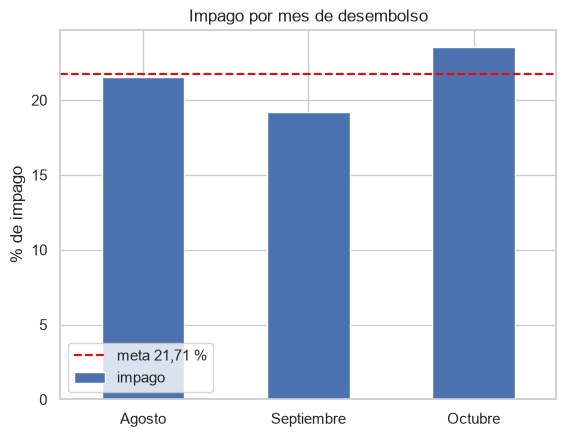

,creditos,impago
MES,,
8,68002,21.567013
9,66788,19.187579
10,98364,23.514701


In [11]:
mes = df.groupby("MES")["LOAN_DEFAULT"].agg(creditos="size", impago="mean")
mes["impago"] *= 100
ax = mes["impago"].plot.bar(color="#4C72B0", rot=0)
ax.axhline(LIMITE, color="red", ls="--", label="meta 21,71 %")
ax.set_xticklabels(["Agosto", "Septiembre", "Octubre"])
ax.set(xlabel="", ylabel="% de impago", title="Impago por mes de desembolso"); ax.legend()
plt.savefig("graficos/09_impago_mes.png", dpi=150, bbox_inches="tight"); plt.show()
mes

**Observación:** agosto 21,6 %, septiembre 19,2 % y octubre 23,5 %: el riesgo cambia de un mes a otro. Por eso la partición es temporal (entrenar con agosto – septiembre y validar con octubre) y por eso el modelo subestima el impago de octubre, un mes peor que los de entrenamiento.

### 3 hallazgos (específicos, cuantificados y prudentes)
1. **El LTV es la señal más clara del préstamo:** el impago sube de 13,9 % (LTV ≤ 60 %) a 25,9 % (80 – 90 %); quienes no pagan financian en mediana 79 % del vehículo frente a 76 % de quienes pagan.
2. **La sucursal marca grandes diferencias:** entre sucursales con más de 1 000 créditos el impago va de 13,3 % a 34,4 %, y 39 de 82 sucursales (44,5 % de los créditos) superan la meta de 21,71 %.
3. **La regla del buró se queda corta:** aunque el impago sube de 15,8 % a 30,2 % con el riesgo del buró, la mitad de los clientes no tiene historial (23,1 % de impago) y la regla no puede distinguir entre ellos.

**Lo que estos datos NO permiten concluir:** que una sucursal o un perfil *cause* el impago (son asociaciones), ni cómo habrían pagado los solicitantes rechazados, porque el archivo solo contiene créditos aprobados.